# Klasifikasi Multilabel: Emotions Dataset

Dataset Emotions memuat fitur akustik dari klip musik 30 detik untuk mendeteksi emosi yang terkandung di dalamnya. Satu lagu bisa menyampaikan beberapa perasaan secara bersamaan. Dataset ini bersumber dari repositori benchmark Mulan (Multi-Label Learning Library).

- Nama dataset: Emotions
- Sumber data: Mulan MLC Datasets Repository
- Link halaman resmi: http://mulan.sourceforge.net/datasets-mlc.html
- Link unduhan arsip: https://downloads.sourceforge.net/project/mulan/datasets/emotions.rar
- Dimensi data: 593 baris dan 78 kolom (72 fitur audio dan 6 label emosi)
- Label target: `amazed-suprised`, `happy-pleased`, `relaxing-calm`, `quiet-still`, `sad-lonely`, dan `angry-aggresive`

In [1]:
import os
import subprocess
import urllib.request
import tempfile
import pandas as pd
from scipy.io import arff

tmpdir = tempfile.gettempdir()
rar_path = os.path.join(tmpdir, "emotions.rar")
extract_dir = os.path.join(tmpdir, "emotions_extracted") + "/"
os.makedirs(extract_dir, exist_ok=True)

if not os.path.exists(rar_path):
    url = "https://downloads.sourceforge.net/project/mulan/datasets/emotions.rar"
    urllib.request.urlretrieve(url, rar_path)

subprocess.run(["unrar", "x", "-o+", rar_path, extract_dir], check=True, stdout=subprocess.DEVNULL)

arff_path = os.path.join(extract_dir, "emotions.arff")
data, meta = arff.loadarff(arff_path)
df = pd.DataFrame(data)

target_cols = meta.names()[-6:]
for col in target_cols:
    df[col] = df[col].astype(str).str.replace("b'", "").str.replace("'", "").astype(int)

print("Shape data:", df.shape)
display(df.head())
print("\nTipe data:")
print(df.dtypes)

Shape data: (593, 78)


,Mean_Acc1298_Mean_Mem40_Centroid,Mean_Acc1298_Mean_Mem40_Rolloff,Mean_Acc1298_Mean_Mem40_Flux,Mean_Acc1298_Mean_Mem40_MFCC_0,Mean_Acc1298_Mean_Mem40_MFCC_1,Mean_Acc1298_Mean_Mem40_MFCC_2,Mean_Acc1298_Mean_Mem40_MFCC_3,Mean_Acc1298_Mean_Mem40_MFCC_4,Mean_Acc1298_Mean_Mem40_MFCC_5,Mean_Acc1298_Mean_Mem40_MFCC_6,...,BH_HighLowRatio,BHSUM1,BHSUM2,BHSUM3,amazed-suprised,happy-pleased,relaxing-calm,quiet-still,sad-lonely,angry-aggresive
0,0.034741,0.089665,0.091225,-73.302422,6.215179,0.615074,2.037160,0.804065,1.301409,0.558576,...,2.0,0.245457,0.105065,0.405399,0,1,1,0,0,0
1,0.081374,0.272747,0.085733,-62.584437,3.183163,-0.218145,0.163038,0.620251,0.458514,0.041426,...,2.0,0.343547,0.276366,0.710924,1,0,0,0,0,1
2,0.110545,0.273567,0.084410,-65.235325,2.794964,0.639047,1.281297,0.757896,0.489412,0.627636,...,3.0,0.188693,0.045941,0.457372,0,1,0,0,0,1
3,0.042481,0.199281,0.093447,-80.305152,5.824409,0.648848,1.754870,1.495532,0.739909,0.809644,...,2.0,0.102839,0.241934,0.351009,0,0,1,0,0,0
4,0.074550,0.140880,0.079789,-93.697749,5.543229,1.064262,0.899152,0.890336,0.702328,0.490685,...,2.0,0.195196,0.310801,0.683817,0,0,0,1,0,0



Tipe data:
Mean_Acc1298_Mean_Mem40_Centroid    float64
Mean_Acc1298_Mean_Mem40_Rolloff     float64
Mean_Acc1298_Mean_Mem40_Flux        float64
Mean_Acc1298_Mean_Mem40_MFCC_0      float64
Mean_Acc1298_Mean_Mem40_MFCC_1      float64
                                     ...   
happy-pleased                         int64
relaxing-calm                         int64
quiet-still                           int64
sad-lonely                            int64
angry-aggresive                       int64
Length: 78, dtype: object


Jumlah label            : 6
Label cardinality       : 1.868  (rata-rata label per baris)
Label density           : 0.311
Baris dengan >1 label   : 70.0%
Baris tanpa label       : 0.0%
=> Multilabel


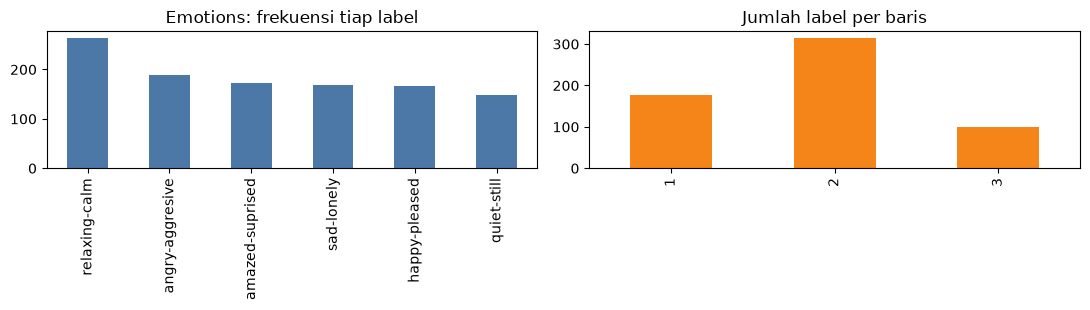

In [2]:
import matplotlib.pyplot as plt

def check_multilabel(Y, title):
    Y = pd.DataFrame(Y)
    per_row = Y.sum(axis=1)
    print(f"Jumlah label            : {Y.shape[1]}")
    print(f"Label cardinality       : {per_row.mean():.3f}  (rata-rata label per baris)")
    print(f"Label density           : {per_row.mean() / Y.shape[1]:.3f}")
    print(f"Baris dengan >1 label   : {(per_row > 1).mean():.1%}")
    print(f"Baris tanpa label       : {(per_row == 0).mean():.1%}")
    print("=> Multilabel" if (per_row > 1).any() else "=> Bukan multilabel (tidak ada baris dengan >1 label)")
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
    Y.sum().sort_values(ascending=False).plot(kind="bar", ax=axes[0], color="#4C78A8")
    axes[0].set_title(f"{title}: frekuensi tiap label")
    per_row.value_counts().sort_index().plot(kind="bar", ax=axes[1], color="#F58518")
    axes[1].set_title("Jumlah label per baris")
    plt.tight_layout()
    plt.show()

check_multilabel(df[target_cols], "Emotions")

In [3]:
assert len(target_cols) == 6, f"Jumlah label harus 6, didapat: {len(target_cols)}"
assert (df[target_cols].sum(axis=1) > 1).sum() > 0, "Harus terdapat baris dengan lebih dari 1 label"
assert df[target_cols].sum(axis=1).mean() > 1.0, "Label cardinality harus > 1.0"
assert df.shape == (593, 78), f"Bentuk dataframe tidak sesuai: {df.shape}"

for col in target_cols:
    assert set(df[col].unique()).issubset({0, 1}), f"Kolom target {col} harus bernilai biner 0/1"

print("Semua verifikasi lolos.")

Semua verifikasi lolos.


## Kesimpulan

Dataset Emotions terbukti masuk dalam kategori klasifikasi multilabel:
1. Target terbagi di 6 kolom terpisah bernilai biner 0 dan 1.
2. Terdapat 415 baris (69,98% dari total 593 baris) yang memiliki lebih dari satu label aktif secara bersamaan.
3. Nilai label cardinality tercatat sebesar 1,8685 dengan label density 0,3114.
4. Tidak ada baris yang kosong tanpa label (0%).